In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
df = pd.read_csv("/content/sample_data/emails.csv")

In [ ]:
print(df.shape)

(2081, 3002)


In [ ]:
print(df.head())

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...       0.0  0.0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...       0.0  0.0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...       0.0  0.0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...       0.0  0.0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...       0.0  0.0   

   valued  lay  infrastructure  military  allowing   ff  dry  Prediction  
0     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
1     0.0  0.0             0.0       0.0       0.0  1.0  0.0         0.0  
2     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
3     0.0  0.0             0.0       0.0       0.0  0.0  0.0         0.0  
4     0.0  0.0             0.0       0.0       0.0  1.0  0.0         0.0  

[5 rows x 3002 columns]


In [ ]:
print("Missing values in y:", y.isnull().sum())
print(y.value_counts(dropna=False))

Missing values in y: 1
Prediction
0.0    1496
1.0     584
NaN       1
Name: count, dtype: int64


In [ ]:
df = df.dropna(subset=[df.columns[-1]])

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

X = X.fillna(0)

print("Missing X:", X.isnull().sum().sum())
print("Missing y:", y.isnull().sum())

Missing X: 0
Missing y: 0


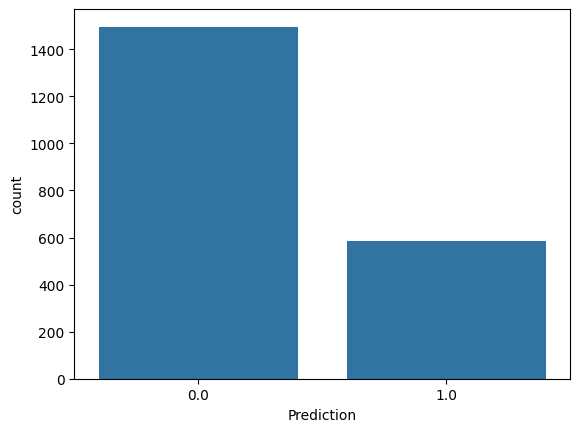

In [ ]:
sns.countplot(x=y)
plt.show()


In [ ]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.30, random_state=0
)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))


KNN Accuracy: 0.7676282051282052


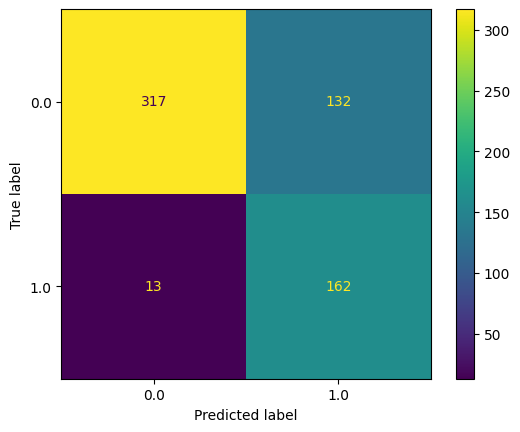

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn)
plt.show()

In [ ]:
error = []

for k in range(1, 34):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    error.append(np.mean(pred != y_test))

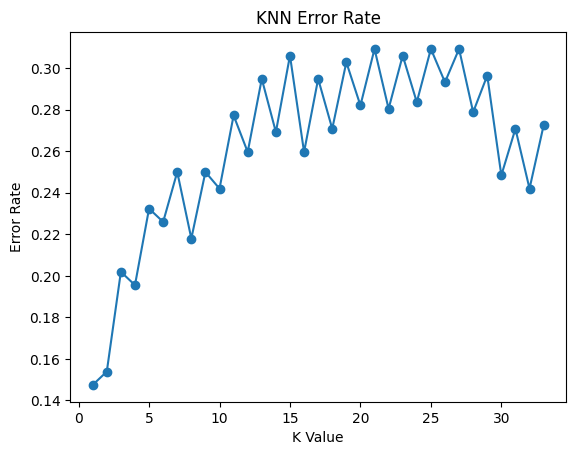

In [ ]:
plt.plot(range(1, 34), error, marker='o')
plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("KNN Error Rate")
plt.show()


In [33]:
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))



SVM Accuracy: 0.9407051282051282


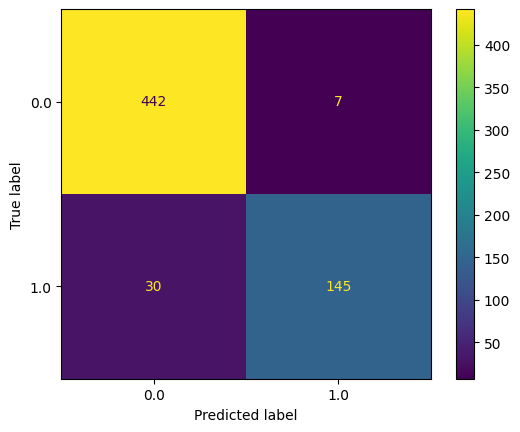

In [34]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm)
plt.show()